# Trabajo 5 · Identificación de estrés con señales fisiológicas (WESAD)
**Entornos Inteligentes**

Servicio de **apoyo al bienestar** para un espejo inteligente: estima si una ventana de señales fisiológicas es compatible con estrés, con una confianza asociada, y propone acciones **voluntarias**. No ofrece diagnósticos.

**Índice**
1. Configuración
2. Extracción de features (EDA, HRV, RESP, EMG, ACC y TEMP en pecho; EDA + HRV + TEMP en muñeca)
3. Marco de evaluación (LOSO)
4. Métodos base (baselines)
5. Modelos clásicos
6. Personalización por usuario
7. Ablaciones (modalidades, pecho vs muñeca)
8. Modelos secuenciales (LSTM y CNN 1D)
9. Comparativa final y elección del modelo
10. Variación entre personas y análisis de errores
11. Incertidumbre y abstención
12. Exportación para el Notebook 2 y limitaciones

## 1. Configuración
Instalación de dependencias, imports, semillas, hilos y parámetros globales.

In [ ]:
import os

# Si WESAD_PATH está definido se usa esa carpeta; si no, se descarga de Kaggle.
if os.environ.get("WESAD_PATH"):
    path = None
else:
    import kagglehub
    path = kagglehub.dataset_download("orvile/wesad-wearable-stress-affect-detection-dataset")
    print("Path to dataset files:", path)

Using Colab cache for faster access to the 'wesad-wearable-stress-affect-detection-dataset' dataset.
Path to dataset files: /kaggle/input/wesad-wearable-stress-affect-detection-dataset


In [2]:
import os, random, pickle, warnings
import numpy as np
import pandas as pd
import joblib
import neurokit2 as nk
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from scipy.signal import butter, sosfiltfilt, find_peaks

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.calibration import calibration_curve
from sklearn.metrics import (accuracy_score, f1_score, matthews_corrcoef, roc_auc_score,
                             confusion_matrix, precision_score, recall_score, brier_score_loss)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

# ajustes gráficos
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 16
mpl.rcParams['axes.labelsize'] = 14
sns.set_context('talk', font_scale=0.8)

# reproducibilidad y recursos
SEED = 42
N_JOBS = 4                      # hilos para RF / XGBoost / KNN
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# rutas
DATA_PATH = os.environ.get("WESAD_PATH") or os.path.join(path, "WESAD")
OUT_POSTER = os.environ.get("OUT_POSTER", "./outputs")
os.makedirs(OUT_POSTER, exist_ok=True)

# parámetros
FS_LABEL = 700                  # frecuencia de las etiquetas (y del RespiBAN en pecho)
SUBJECT_IDS = [f"S{i}" for i in range(2, 12)] + [f"S{i}" for i in range(13, 18)]   # S1 y S12 no existen
COND_NAMES = {1: "Baseline", 2: "Stress", 3: "Amusement", 4: "Meditation"}
WINDOW_SEC, STEP_SEC = 60, 30
SEQ_LEN = 5
N_CALIB = 5                     # ventanas baseline usadas para calibrar a cada persona

USE_CACHE = False                # reutiliza los CSV de features si ya existen
RUN_WRIST = True                # comparar pecho vs muñeca

## 2. Extracción de features
Para cada ventana se calculan **en la misma ventana**:
- **EDA**: nº de respuestas electrodérmicas (SCR), área de la componente fásica y media de la tónica.
- **HRV**: RMSSD, SDNN, MeanNN, LF, HF y LF/HF a partir de los picos R (pecho, ECG) o del pulso BVP (muñeca).
- **TEMP**: media, desviación y pendiente (pecho y muñeca).
- **RESP** (solo pecho): frecuencia respiratoria, desviación y amplitud media de las respiraciones.
- **EMG** (solo pecho): RMS de la señal filtrada (paso alto a 20 Hz).
- **ACC** (solo pecho): media y desviación de la magnitud de la aceleración.

El modelo principal usa las 18 features de pecho. La versión de muñeca (EDA + HRV + TEMP, 12 features) solo se emplea en la ablación de la sección 7.

Etiqueta binaria: estrés (2) frente a no estrés (baseline, diversión, meditación). Se guarda también la condición original (`Cond`) para analizar errores. Las ventanas con etiquetas no definidas se descartan.

In [ ]:
_trapz = getattr(np, "trapezoid", None) or np.trapz   

def load_subject(path):
    with open(path, "rb") as f:
        return pickle.load(f, encoding="latin1")

def eda_features(eda, fs):
    sos = butter(4, 0.05, btype="low", fs=fs, output="sos")     # SOS: estable con cortes tan bajos
    tonic = sosfiltfilt(sos, eda)
    phasic = eda - tonic
    peaks, _ = find_peaks(phasic, height=0.01, distance=int(fs))
    return {"EDA_SCR_count": len(peaks),
            "EDA_Phasic_AUC": _trapz(np.abs(phasic)) / fs,
            "EDA_Tonic_Mean": float(np.mean(tonic))}

def temp_features(temp, fs):
    t = np.arange(len(temp)) / fs
    return {"TEMP_Mean": float(temp.mean()), "TEMP_Std": float(temp.std()),
            "TEMP_Slope": float(np.polyfit(t, temp, 1)[0])}

def hrv_features(peaks_idx, fs):
    rr_ms = np.diff(peaks_idx) / fs * 1000
    rr_ms = rr_ms[(rr_ms > 300) & (rr_ms < 2000)]          # descarta intervalos  imposibles
    if len(rr_ms) < 10:
        return None
    try:
        pk = nk.intervals_to_peaks(rr_ms, sampling_rate=fs)
        t = nk.hrv_time(pk, sampling_rate=fs, show=False)
        f = nk.hrv_frequency(pk, sampling_rate=fs, show=False)
        out = {"HRV_RMSSD": t["HRV_RMSSD"].values[0], "HRV_SDNN": t["HRV_SDNN"].values[0],
               "HRV_MeanNN": t["HRV_MeanNN"].values[0], "HRV_LF": f["HRV_LF"].values[0],
               "HRV_HF": f["HRV_HF"].values[0], "HRV_LFHF": f["HRV_LFHF"].values[0]}
        return out if all(np.isfinite(list(out.values()))) else None
    except Exception:
        return None

def get_peaks(subject, source):
    if source == "chest":
        ecg = subject["signal"]["chest"]["ECG"].ravel()
        cleaned = nk.ecg_clean(ecg, sampling_rate=700)
        _, info = nk.ecg_peaks(cleaned, sampling_rate=700)
        return np.asarray(info["ECG_R_Peaks"]), 700
    bvp = subject["signal"]["wrist"]["BVP"].ravel()
    cleaned = nk.ppg_clean(bvp, sampling_rate=64)
    _, info = nk.ppg_peaks(cleaned, sampling_rate=64)
    return np.asarray(info["PPG_Peaks"]), 64

def resp_features(resp, fs):
    sos = butter(2, [0.1, 0.5], btype="band", fs=fs, output="sos")
    r = sosfiltfilt(sos, resp - resp.mean())
    pk, _ = find_peaks(r, distance=int(2 * fs))              # respiraciones separadas ≥2 s
    return {"RESP_Rate": len(pk) / (len(resp) / fs / 60),    # resp./min
            "RESP_Std": float(r.std()),
            "RESP_Amp": float(np.mean(r[pk])) if len(pk) else 0.0}

def emg_features(emg, fs):
    sos = butter(4, 20, btype="high", fs=fs, output="sos")
    e = sosfiltfilt(sos, emg)
    return {"EMG_RMS": float(np.sqrt(np.mean(e ** 2)))}

def acc_features(acc, fs):                                   # acc: (N, 3)
    mag = np.linalg.norm(acc, axis=1)
    return {"ACC_Mean": float(mag.mean()), "ACC_Std": float(mag.std())}

def extract_subject(subject, source, window_sec, step_sec):
    labels = subject["label"]
    if source == "chest":
        eda, fs_eda = subject["signal"]["chest"]["EDA"].ravel(), 700
        temp, fs_temp = subject["signal"]["chest"]["Temp"].ravel(), 700
    else:
        eda, fs_eda = subject["signal"]["wrist"]["EDA"].ravel(), 4
        temp, fs_temp = subject["signal"]["wrist"]["TEMP"].ravel(), 4
    peaks, fs_peak = get_peaks(subject, source)

    n_sec = int(len(labels) / FS_LABEL)
    rows = []
    for t0 in range(0, n_sec - window_sec + 1, step_sec):
        t1 = t0 + window_sec
        maj = np.bincount(labels[t0 * FS_LABEL:t1 * FS_LABEL]).argmax()
        if maj not in COND_NAMES:
            continue
        e = eda[t0 * fs_eda:t1 * fs_eda]
        if np.isnan(e).any():
            continue
        p = peaks[(peaks >= t0 * fs_peak) & (peaks < t1 * fs_peak)] - t0 * fs_peak
        h = hrv_features(p, fs_peak)
        if h is None:
            continue
        row = {"Time": t0, "Cond": COND_NAMES[maj], "Label": int(maj == 2)}
        row.update(eda_features(e, fs_eda))
        row.update(h)
        if temp is not None:
            row.update(temp_features(temp[t0 * fs_temp:t1 * fs_temp], fs_temp))
        if source == "chest":
            ch, sl = subject["signal"]["chest"], slice(t0 * 700, t1 * 700)
            row.update(resp_features(ch["Resp"].ravel()[sl], 700))
            row.update(emg_features(ch["EMG"].ravel()[sl], 700))
            row.update(acc_features(ch["ACC"][sl], 700))
        rows.append(row)
    return pd.DataFrame(rows)

def extract_all(source, window_sec, step_sec):
    cache = os.path.join(OUT_POSTER, f"features_{source}_{window_sec}s_{step_sec}s.csv")
    if USE_CACHE and os.path.exists(cache):
        print("Cargado desde caché:", cache)
        return pd.read_csv(cache)
    dfs = []
    for sid in SUBJECT_IDS:
        subj = load_subject(f"{DATA_PATH}/{sid}/{sid}.pkl")
        d = extract_subject(subj, source, window_sec, step_sec)
        d.insert(0, "Subject", sid)
        dfs.append(d)
        print(sid, len(d), end=" | ")
    df = pd.concat(dfs, ignore_index=True)
    df.to_csv(cache, index=False)
    print("\nGuardado en", cache)
    return df

def feat_cols(df):
    return [c for c in df.columns if c not in ("Subject", "Time", "Cond", "Label")]

### Extracción principal (pecho, ventana de 60 s)

In [4]:
DF = extract_all("chest", WINDOW_SEC, STEP_SEC)
COLS_ALL = feat_cols(DF)

S2 96 | S3 99 | S4 99 | S5 99 | S6 99 | S7 99 | S8 100 | S9 99 | S10 103 | S11 102 | S13 102 | S14 102 | S15 101 | S16 99 | S17 100 | 
Guardado en ./outputs/features_chest_60s_30s.csv


In [5]:
print("Ventanas totales:", len(DF), "| sujetos:", DF.Subject.nunique())
print("\nEtiqueta binaria (1 = estrés):");  print(DF.Label.value_counts().to_string())
print("\nCondición original:");             print(DF.Cond.value_counts().to_string())
print("\nVentanas por sujeto:");            print(DF.groupby("Subject").size().to_string())
display(DF[COLS_ALL].describe().T[["mean", "std"]].round(3))

Ventanas totales: 1499 | sujetos: 15

Etiqueta binaria (1 = estrés):
Label
0    1167
1     332

Condición original:
Cond
Baseline      587
Meditation    394
Stress        332
Amusement     186

Ventanas por sujeto:
Subject
S10    103
S11    102
S13    102
S14    102
S15    101
S16     99
S17    100
S2      96
S3      99
S4      99
S5      99
S6      99
S7      99
S8     100
S9      99


,mean,std
EDA_SCR_count,43.164,4.029
EDA_Phasic_AUC,0.953,1.284
EDA_Tonic_Mean,4.603,3.352
HRV_RMSSD,56.080,37.800
HRV_SDNN,76.733,36.407
HRV_MeanNN,809.030,151.389
HRV_LF,0.035,0.017
HRV_HF,0.027,0.025
HRV_LFHF,2.734,3.080
TEMP_Mean,33.875,1.227


## 3. Marco de evaluación
Validación **leave-one-subject-out (LOSO)**: en cada iteración se entrena con 14 personas y se prueba con la restante. Se guardan las probabilidades fuera de muestra (`OOF`) y se calculan las métricas **por sujeto**, para ver la variación entre personas (se reporta media ± desviación entre sujetos). Umbral de decisión: 0,5.

In [6]:
logo = LeaveOneGroupOut()
OOF, RES, MAIN_NAMES = {}, {}, []
METRICS = ["Acc", "F1", "MCC", "AUC", "Recall", "Specificity"]

def loso_oof(make_model, df, cols):
    X = df[cols].reset_index(drop=True)
    y = df["Label"].values
    g = df["Subject"].values
    p = np.zeros(len(df))
    for tr, te in logo.split(X, y, g):
        model = make_model(y[tr])
        model.fit(X.iloc[tr], y[tr])
        p[te] = model.predict_proba(X.iloc[te])[:, 1]
    return pd.DataFrame({"Subject": g, "Time": df["Time"].values, "Cond": df["Cond"].values, "y": y, "p": p})

def subject_metrics(oof, thr=0.5):
    rows = []
    for s, d in oof.groupby("Subject"):
        yhat = (d.p >= thr).astype(int)
        tn, fp, fn, tp = confusion_matrix(d.y, yhat, labels=[0, 1]).ravel()
        try:
            auc = roc_auc_score(d.y, d.p)
        except ValueError:
            auc = np.nan
        rows.append({"Subject": s, "Acc": accuracy_score(d.y, yhat),
                     "F1": f1_score(d.y, yhat, zero_division=0),
                     "MCC": matthews_corrcoef(d.y, yhat), "AUC": auc,
                     "Precision": precision_score(d.y, yhat, zero_division=0),
                     "Recall": recall_score(d.y, yhat, zero_division=0),
                     "Specificity": tn / (tn + fp) if (tn + fp) else np.nan,
                     "FPR": fp / (tn + fp) if (tn + fp) else np.nan})
    return pd.DataFrame(rows).set_index("Subject")

def register(name, oof, main=False):
    OOF[name] = oof
    RES[name] = subject_metrics(oof)
    if main and name not in MAIN_NAMES:
        MAIN_NAMES.append(name)

def plot_cm(oof, title):
    cm = confusion_matrix(oof.y, (oof.p >= 0.5).astype(int), labels=[0, 1])
    plt.figure(figsize=(3.6, 3))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=["No estrés", "Estrés"], yticklabels=["No estrés", "Estrés"])
    plt.title(f"{title} (LOSO)"); plt.xlabel("Predicho"); plt.ylabel("Real")
    plt.tight_layout(); plt.savefig(f'{OUT_POSTER}/CM_{title}.png', bbox_inches='tight')
    plt.show()

def run_model(name, make_model, df, cols, plot=True, verbose=True, main=False):
    oof = loso_oof(make_model, df, cols)
    register(name, oof, main)
    if verbose:
        sm = RES[name]
        print(f"{name}: Acc {sm.Acc.mean():.3f}±{sm.Acc.std():.3f} | F1 {sm.F1.mean():.3f}±{sm.F1.std():.3f} | "
              f"MCC {sm.MCC.mean():.3f}±{sm.MCC.std():.3f} | AUC {sm.AUC.mean():.3f}±{sm.AUC.std():.3f}")
    if plot:
        plot_cm(oof, name)

def means_table(names):
    return pd.DataFrame({n: RES[n][METRICS].mean() for n in names}).T

def summary_table(names):
    out = {}
    for n in names:
        sm = RES[n]
        out[n] = {m: f"{sm[m].mean():.3f}±{sm[m].std():.3f}" for m in METRICS}
    return pd.DataFrame(out).T

## 4. Métodos base (baselines)
Referencia mínima para valorar si los modelos aportan algo:
1. **Clase mayoritaria** (siempre predice "no estrés").
2. **Umbral sobre una sola feature**: regresión logística con solo `EDA_Tonic_Mean`.

Baseline_mayoritaria: Acc 0.779±0.009 | F1 0.000±0.000 | MCC 0.000±0.000 | AUC 0.500±0.000


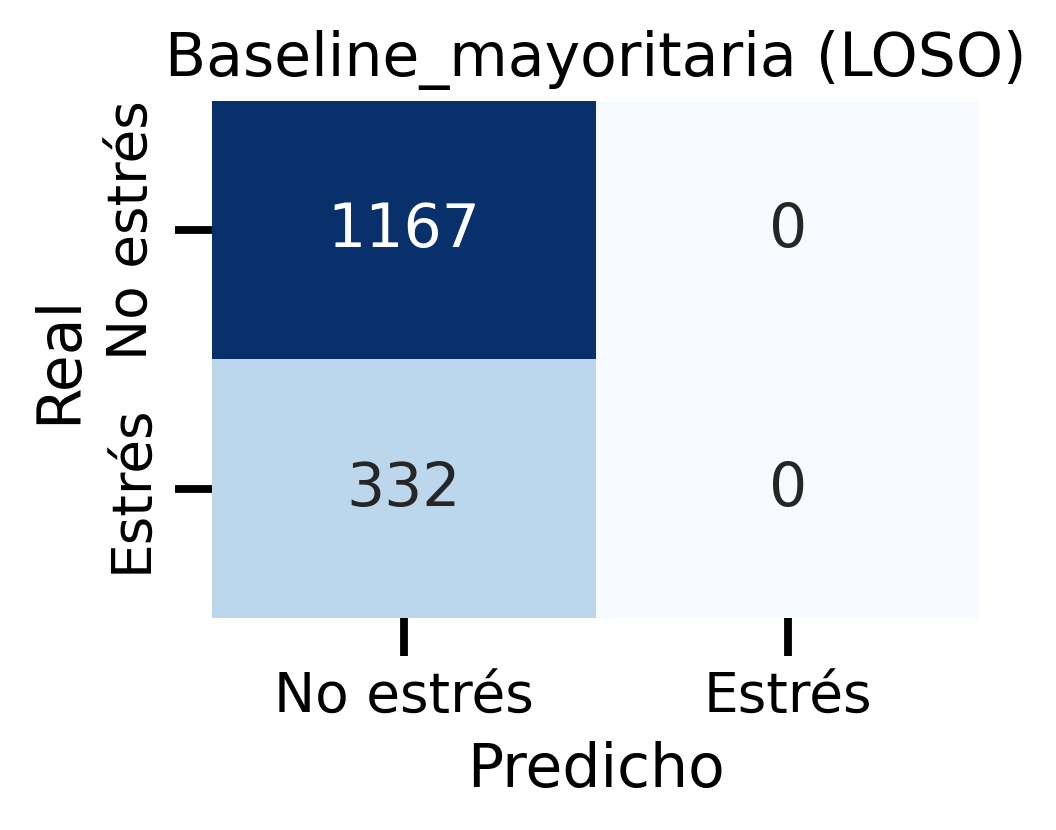

In [7]:
run_model("Baseline_mayoritaria", lambda ytr: DummyClassifier(strategy="most_frequent"), DF, COLS_ALL)

Baseline_umbral_EDA: Acc 0.584±0.270 | F1 0.184±0.206 | MCC 0.057±0.152 | AUC 0.904±0.110


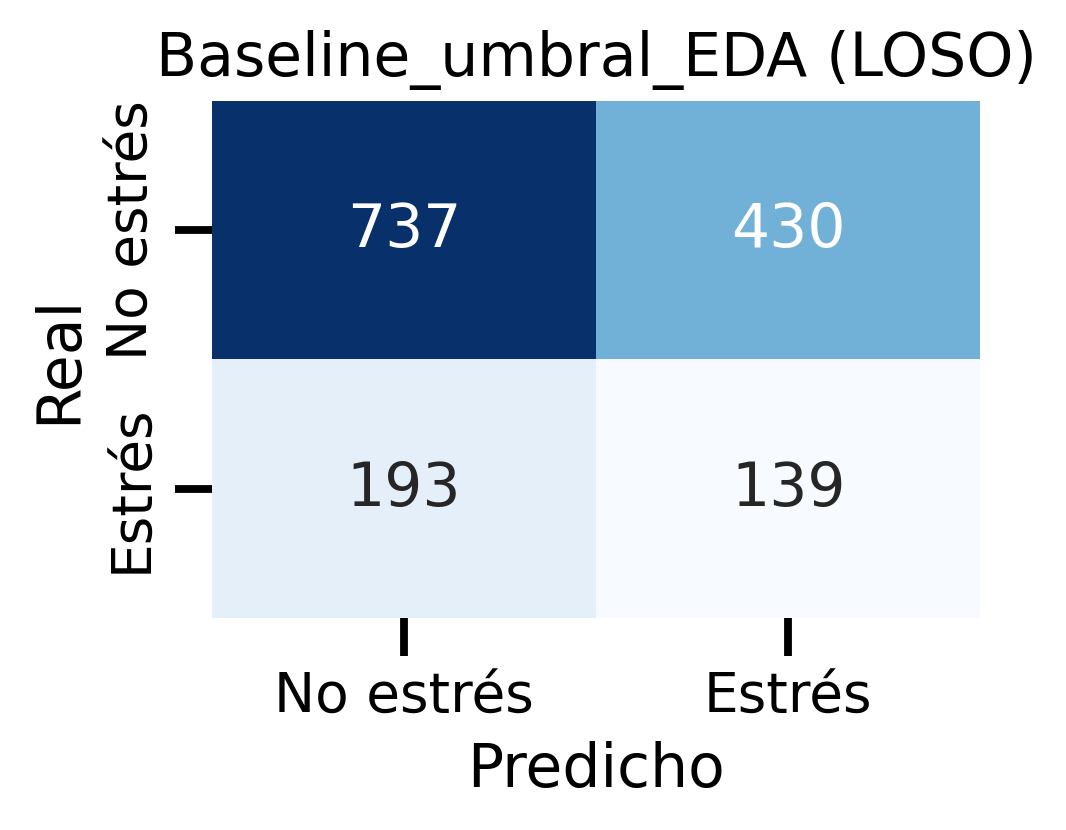

In [8]:
run_model("Baseline_umbral_EDA",
          lambda ytr: Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(class_weight="balanced", max_iter=1000))]),
          DF, ["EDA_Tonic_Mean"])

## 5. Modelos clásicos
Se entrenan con todas las features (sin personalizar). 

In [9]:
MODELS = {
    "SVM": lambda ytr: Pipeline([("sc", StandardScaler()),
                                 ("m", SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=SEED))]),
    "RF": lambda ytr: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight="balanced",
                                             n_jobs=N_JOBS, random_state=SEED),
    "XGBoost": lambda ytr: XGBClassifier(n_estimators=300, max_depth=4, learning_rate=0.05, subsample=0.8,
                                         colsample_bytree=0.8, eval_metric="logloss", verbosity=0,
                                         scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum(),   # solo con el train del fold
                                         n_jobs=N_JOBS, random_state=SEED),
    "LR": lambda ytr: Pipeline([("sc", StandardScaler()),
                                ("m", LogisticRegression(class_weight="balanced", max_iter=1000))]),
    "AdaBoost": lambda ytr: AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=2, min_samples_leaf=5, class_weight="balanced", random_state=SEED),
        n_estimators=200, learning_rate=0.5, random_state=SEED),
    "KNN": lambda ytr: Pipeline([("sc", StandardScaler()),
                                 ("m", KNeighborsClassifier(n_neighbors=7, weights="distance", n_jobs=N_JOBS))]),
}


SVM: Acc 0.904±0.090 | F1 0.697±0.336 | MCC 0.695±0.319 | AUC 0.928±0.160


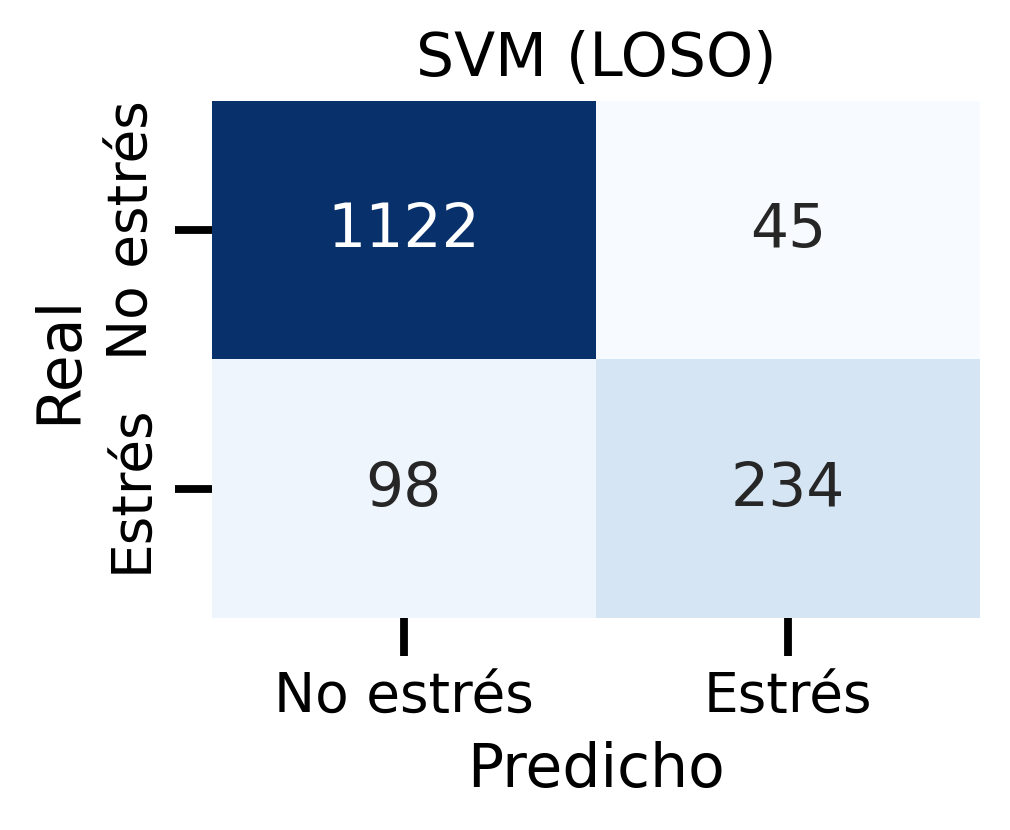

In [10]:
run_model("SVM", MODELS["SVM"], DF, COLS_ALL, main=True)

RF: Acc 0.929±0.056 | F1 0.829±0.146 | MCC 0.804±0.159 | AUC 0.984±0.029


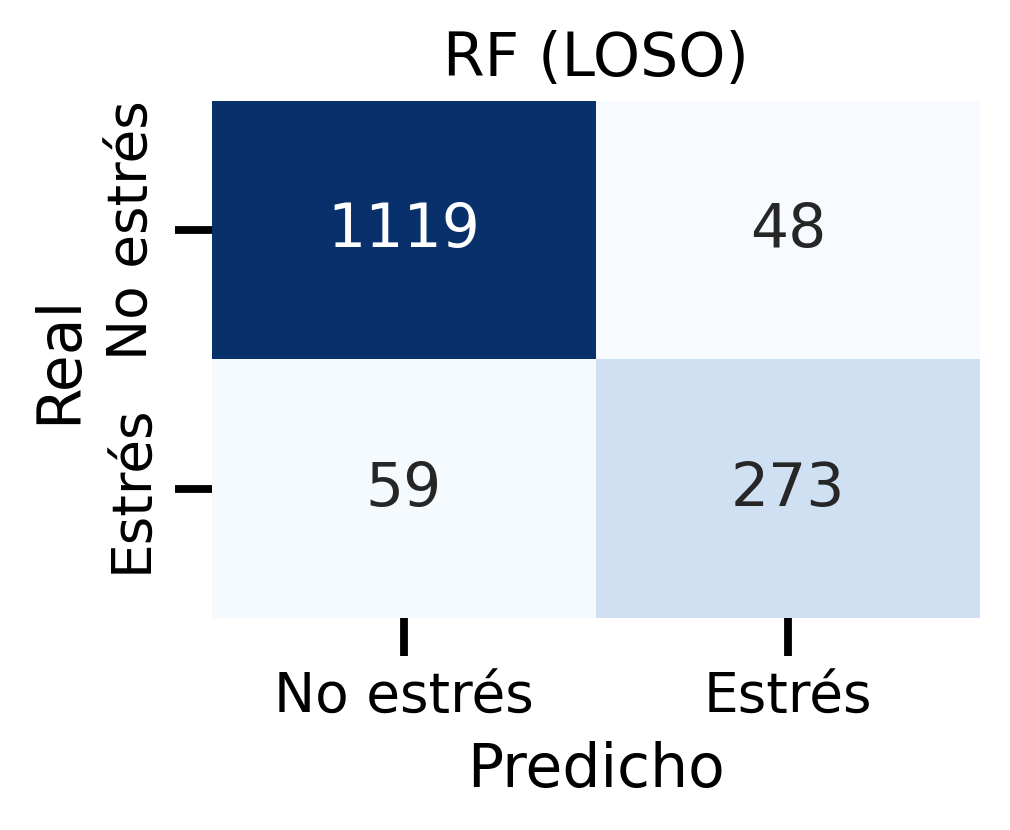

In [11]:
run_model("RF", MODELS["RF"], DF, COLS_ALL, main=True)

XGBoost: Acc 0.932±0.057 | F1 0.835±0.146 | MCC 0.814±0.152 | AUC 0.990±0.018


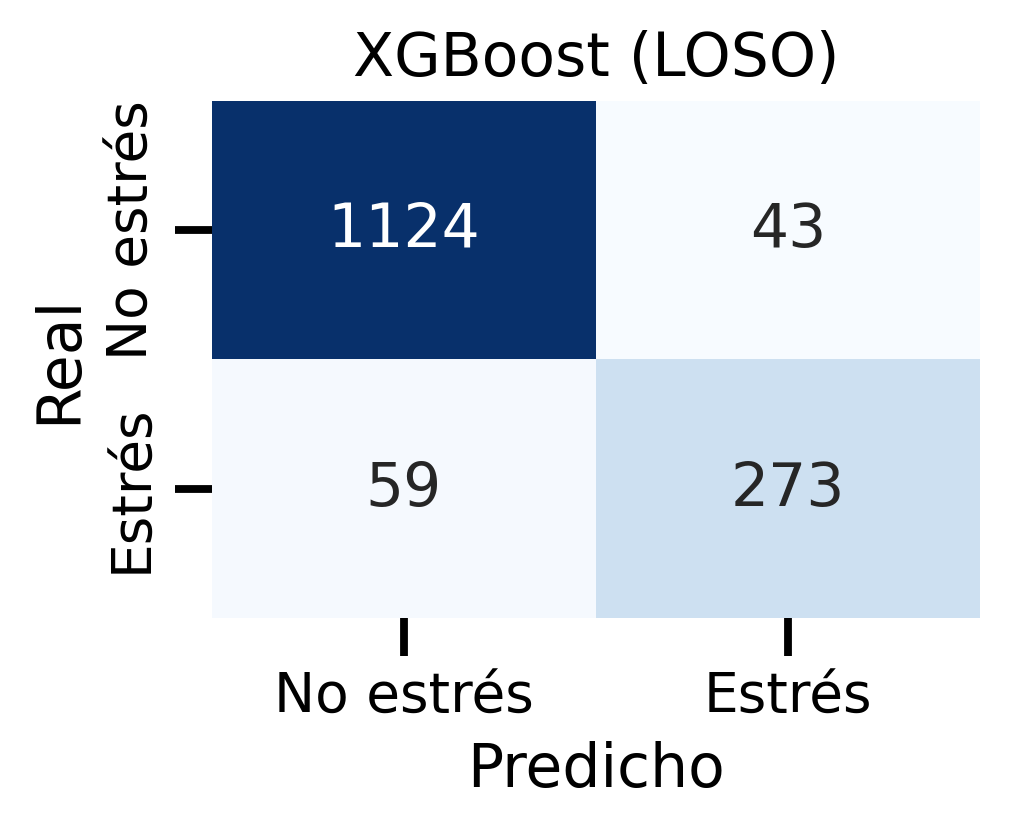

In [12]:
run_model("XGBoost", MODELS["XGBoost"], DF, COLS_ALL, main=True)

LR: Acc 0.887±0.121 | F1 0.737±0.278 | MCC 0.723±0.259 | AUC 0.971±0.047


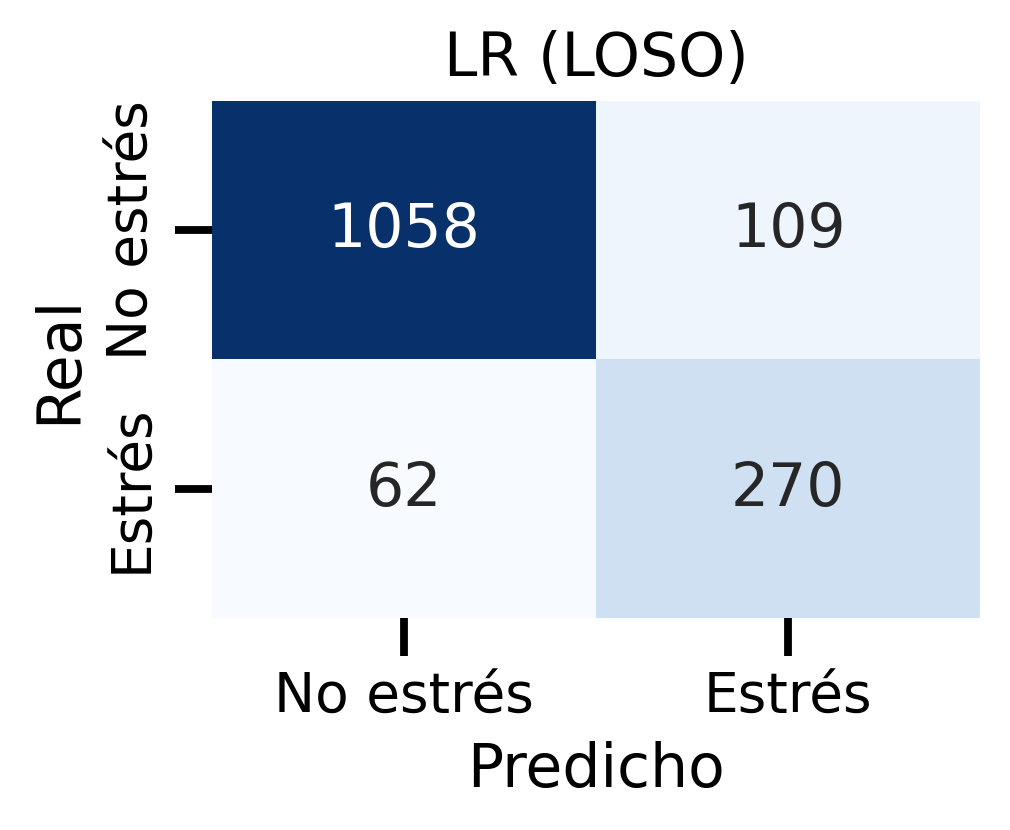

In [13]:
run_model("LR", MODELS["LR"], DF, COLS_ALL, main=True)

AdaBoost: Acc 0.894±0.090 | F1 0.757±0.222 | MCC 0.730±0.227 | AUC 0.966±0.070


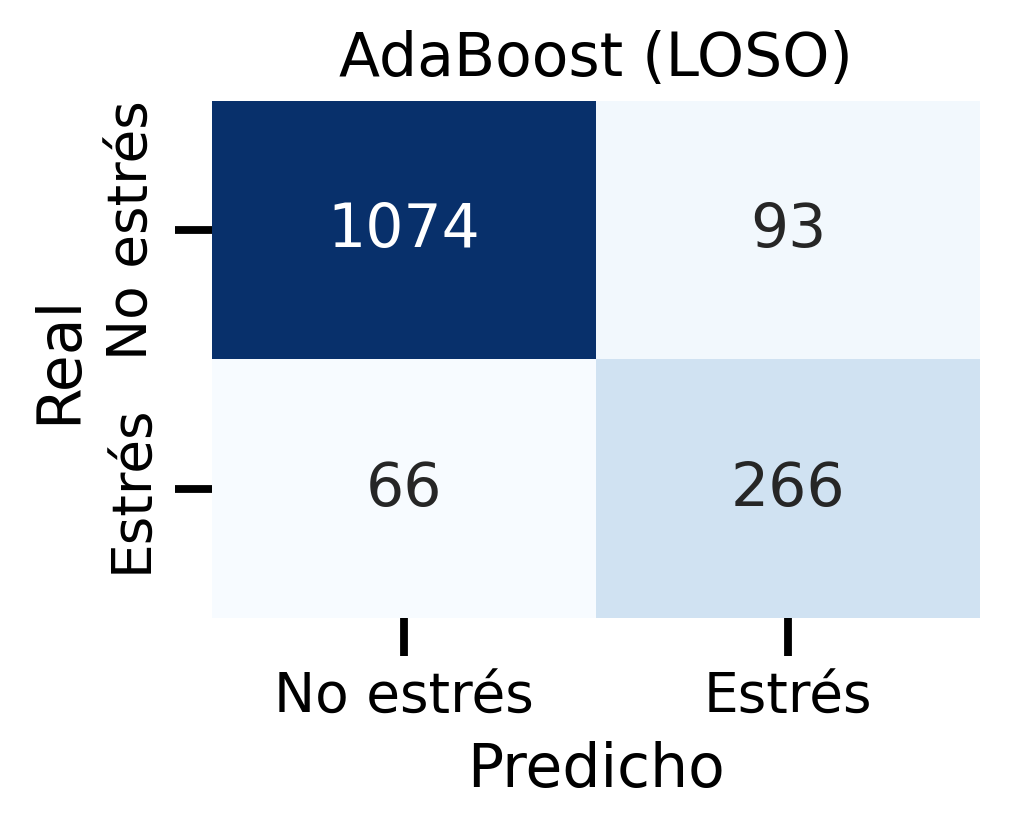

In [14]:
run_model("AdaBoost", MODELS["AdaBoost"], DF, COLS_ALL, main=True)

KNN: Acc 0.889±0.076 | F1 0.663±0.302 | MCC 0.638±0.304 | AUC 0.886±0.156


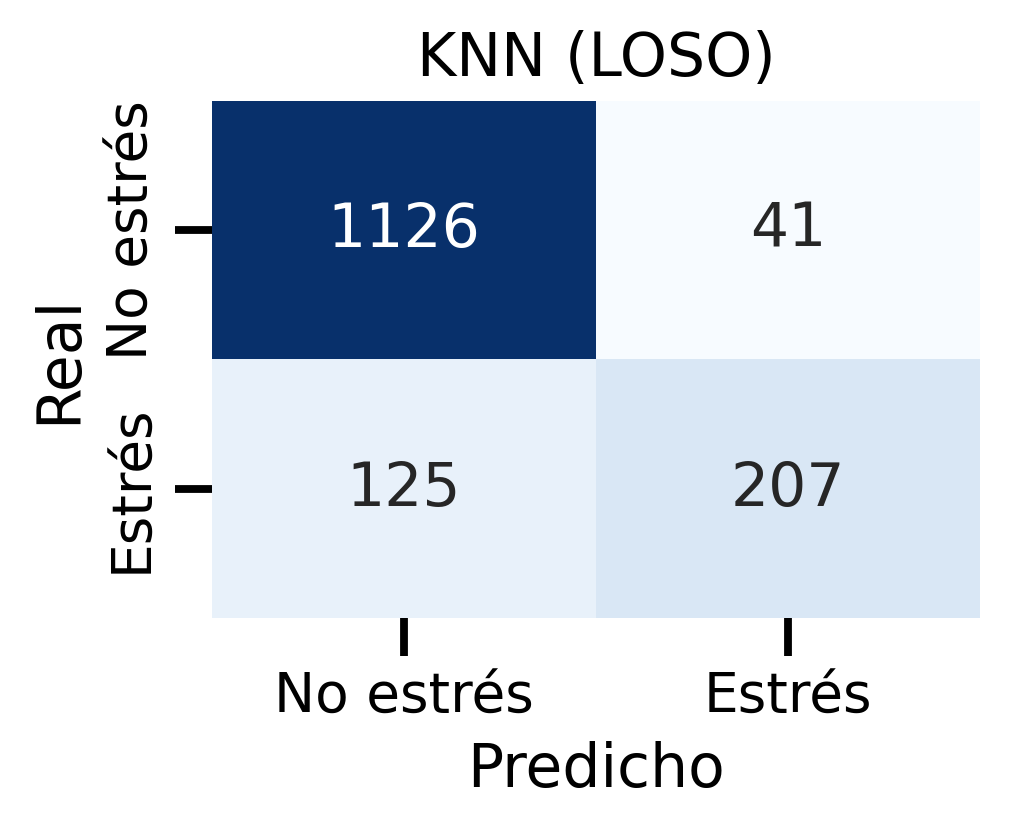

In [15]:
run_model("KNN", MODELS["KNN"], DF, COLS_ALL, main=True)

### Resumen: baselines y modelos clásicos (media ± desviación entre sujetos)

In [16]:
display(summary_table(["Baseline_mayoritaria", "Baseline_umbral_EDA"] + list(MODELS)))

,Acc,F1,MCC,AUC,Recall,Specificity
Baseline_mayoritaria,0.779±0.009,0.000±0.000,0.000±0.000,0.500±0.000,0.000±0.000,1.000±0.000
Baseline_umbral_EDA,0.584±0.270,0.184±0.206,0.057±0.152,0.904±0.110,0.418±0.497,0.630±0.482
SVM,0.904±0.090,0.697±0.336,0.695±0.319,0.928±0.160,0.700±0.395,0.962±0.081
RF,0.929±0.056,0.829±0.146,0.804±0.159,0.984±0.029,0.823±0.213,0.959±0.061
XGBoost,0.932±0.057,0.835±0.146,0.814±0.152,0.990±0.018,0.822±0.214,0.964±0.067
LR,0.887±0.121,0.737±0.278,0.723±0.259,0.971±0.047,0.809±0.342,0.908±0.158
AdaBoost,0.894±0.090,0.757±0.222,0.730±0.227,0.966±0.070,0.800±0.290,0.921±0.119
KNN,0.889±0.076,0.663±0.302,0.638±0.304,0.886±0.156,0.625±0.340,0.965±0.051


## 6. Personalización por usuario
Cada persona tiene niveles fisiológicos distintos. Se normaliza cada feature con la **media y desviación de sus primeras `N_CALIB` ventanas de baseline** (una breve sesión de calibración en reposo). Solo se usa información de esa persona y ninguna etiqueta de estrés.

Para que la comparación sea justa, esas ventanas de calibración se **excluyen de la evaluación** y los modelos "raw" se vuelven a evaluar sobre el mismo conjunto.

In [17]:
def personalize(df, cols, n_calib=N_CALIB):
    out = df.copy()
    out[cols] = out[cols].astype(float)
    calib_mask = pd.Series(False, index=df.index)
    for s, d in df.groupby("Subject"):
        base = d[d.Cond == "Baseline"].sort_values("Time").head(n_calib)
        if len(base) == 0:
            continue
        mu = base[cols].mean()
        sd = base[cols].std().replace(0, 1.0).fillna(1.0)
        out.loc[d.index, cols] = (d[cols] - mu) / sd
        calib_mask.loc[base.index] = True
    return out, calib_mask

DF_P_full, CALIB_MASK = personalize(DF, COLS_ALL)
DF_C = DF[~CALIB_MASK].reset_index(drop=True)          # raw, sin ventanas de calibración
DF_P = DF_P_full[~CALIB_MASK].reset_index(drop=True)   # personalizado, mismas ventanas
print("Ventanas de calibración excluidas:", int(CALIB_MASK.sum()), "| ventanas evaluadas:", len(DF_C))

Ventanas de calibración excluidas: 75 | ventanas evaluadas: 1424


In [18]:
for name, mk in MODELS.items():
    run_model(f"{name}|raw", mk, DF_C, COLS_ALL, plot=False, verbose=False)
    run_model(f"{name}|pers", mk, DF_P, COLS_ALL, plot=False, verbose=False)
run_model("Baseline_umbral_EDA|raw",
          lambda ytr: Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(class_weight="balanced", max_iter=1000))]),
          DF_C, ["EDA_Tonic_Mean"], plot=False, verbose=False)
run_model("Baseline_umbral_EDA|pers",
          lambda ytr: Pipeline([("sc", StandardScaler()), ("lr", LogisticRegression(class_weight="balanced", max_iter=1000))]),
          DF_P, ["EDA_Tonic_Mean"], plot=False, verbose=False)

In [19]:
rows = []
for name in list(MODELS) + ["Baseline_umbral_EDA"]:
    r, p = RES[f"{name}|raw"], RES[f"{name}|pers"]
    rows.append({"Modelo": name,
                 "F1 raw": r.F1.mean(), "F1 pers": p.F1.mean(), "ΔF1": p.F1.mean() - r.F1.mean(),
                 "MCC raw": r.MCC.mean(), "MCC pers": p.MCC.mean(), "ΔMCC": p.MCC.mean() - r.MCC.mean(),
                 "AUC raw": r.AUC.mean(), "AUC pers": p.AUC.mean()})
display(pd.DataFrame(rows).set_index("Modelo").round(3))

,F1 raw,F1 pers,ΔF1,MCC raw,MCC pers,ΔMCC,AUC raw,AUC pers
Modelo,,,,,,,,
SVM,0.701,0.558,-0.143,0.689,0.493,-0.196,0.930,0.847
RF,0.848,0.762,-0.086,0.821,0.729,-0.092,0.985,0.971
XGBoost,0.848,0.749,-0.099,0.824,0.719,-0.105,0.989,0.979
LR,0.764,0.695,-0.069,0.749,0.637,-0.112,0.968,0.905
AdaBoost,0.775,0.694,-0.081,0.742,0.648,-0.094,0.964,0.952
KNN,0.667,0.565,-0.102,0.635,0.545,-0.091,0.886,0.845
Baseline_umbral_EDA,0.191,0.210,0.019,0.059,0.178,0.119,0.911,0.911


## 7. Ablaciones
Qué aporta cada modalidad (EDA, HRV y cada señal añadida: RESP, EMG, ACC, TEMP) y si funciona con señales de muñeca (dispositivo personal). Se usa Random Forest.

Las diferencias entre configuraciones suelen ser menores que la variación entre sujetos. Además, ACC y EMG pueden captar el habla y el movimiento de la tarea de estrés, no solo la respuesta fisiológica.

In [20]:
COLS_EDA  = [c for c in COLS_ALL if c.startswith("EDA")]
COLS_HRV  = [c for c in COLS_ALL if c.startswith("HRV")]
COLS_RESP = [c for c in COLS_ALL if c.startswith("RESP")]
COLS_EMG  = [c for c in COLS_ALL if c.startswith("EMG")]
COLS_ACC  = [c for c in COLS_ALL if c.startswith("ACC")]
COLS_TEMP = [c for c in COLS_ALL if c.startswith("TEMP")]
COLS_BASE = COLS_EDA + COLS_HRV

ABLACIONES = {
    "RF|solo EDA": COLS_EDA,
    "RF|solo HRV": COLS_HRV,
    "RF|EDA+HRV":  COLS_BASE,
    "RF|+RESP":    COLS_BASE + COLS_RESP,
    "RF|+EMG":     COLS_BASE + COLS_EMG,
    "RF|+ACC":     COLS_BASE + COLS_ACC,
    "RF|+TEMP":    COLS_BASE + COLS_TEMP,
}
for n, cols in ABLACIONES.items():
    run_model(n, MODELS["RF"], DF, cols, plot=False)

RF|solo EDA: Acc 0.760±0.137 | F1 0.481±0.236 | MCC 0.432±0.218 | AUC 0.850±0.133
RF|solo HRV: Acc 0.844±0.132 | F1 0.652±0.220 | MCC 0.621±0.228 | AUC 0.927±0.092
RF|EDA+HRV: Acc 0.903±0.108 | F1 0.791±0.212 | MCC 0.752±0.263 | AUC 0.961±0.088
RF|+RESP: Acc 0.909±0.090 | F1 0.793±0.199 | MCC 0.756±0.241 | AUC 0.965±0.080
RF|+EMG: Acc 0.911±0.095 | F1 0.797±0.207 | MCC 0.761±0.251 | AUC 0.961±0.087
RF|+ACC: Acc 0.921±0.074 | F1 0.825±0.141 | MCC 0.798±0.161 | AUC 0.985±0.026
RF|+TEMP: Acc 0.908±0.091 | F1 0.771±0.231 | MCC 0.738±0.266 | AUC 0.963±0.081


In [21]:
if RUN_WRIST:
    DF_W = extract_all("wrist", WINDOW_SEC, STEP_SEC)
    COLS_W = feat_cols(DF_W)
    print("Ventanas muñeca:", len(DF_W), "| features:", COLS_W)
    run_model("RF|muñeca (EDA+BVP+TEMP)", MODELS["RF"], DF_W, COLS_W, plot=False)

S2 94 | S3 82 | S4 99 | S5 75 | S6 98 | S7 97 | S8 100 | S9 99 | S10 94 | S11 82 | S13 102 | S14 102 | S15 77 | S16 93 | S17 93 | 
Guardado en ./outputs/features_wrist_60s_30s.csv
Ventanas muñeca: 1387 | features: ['EDA_SCR_count', 'EDA_Phasic_AUC', 'EDA_Tonic_Mean', 'HRV_RMSSD', 'HRV_SDNN', 'HRV_MeanNN', 'HRV_LF', 'HRV_HF', 'HRV_LFHF', 'TEMP_Mean', 'TEMP_Std', 'TEMP_Slope']
RF|muñeca (EDA+BVP+TEMP): Acc 0.912±0.063 | F1 0.775±0.241 | MCC 0.740±0.245 | AUC 0.974±0.033


In [22]:
abl = list(ABLACIONES) + ["RF"]
if RUN_WRIST: abl.append("RF|muñeca (EDA+BVP+TEMP)")
display(summary_table(abl).rename(index={"RF": "RF|todas (pecho)"}))

,Acc,F1,MCC,AUC,Recall,Specificity
RF|solo EDA,0.760±0.137,0.481±0.236,0.432±0.218,0.850±0.133,0.614±0.393,0.805±0.226
RF|solo HRV,0.844±0.132,0.652±0.220,0.621±0.228,0.927±0.092,0.680±0.317,0.889±0.198
RF|EDA+HRV,0.903±0.108,0.791±0.212,0.752±0.263,0.961±0.088,0.815±0.258,0.930±0.107
RF|+RESP,0.909±0.090,0.793±0.199,0.756±0.241,0.965±0.080,0.818±0.253,0.935±0.079
RF|+EMG,0.911±0.095,0.797±0.207,0.761±0.251,0.961±0.087,0.815±0.257,0.939±0.084
RF|+ACC,0.921±0.074,0.825±0.141,0.798±0.161,0.985±0.026,0.824±0.203,0.950±0.095
RF|+TEMP,0.908±0.091,0.771±0.231,0.738±0.266,0.963±0.081,0.762±0.289,0.951±0.074
RF|todas (pecho),0.929±0.056,0.829±0.146,0.804±0.159,0.984±0.029,0.823±0.213,0.959±0.061
RF|muñeca (EDA+BVP+TEMP),0.912±0.063,0.775±0.241,0.740±0.245,0.974±0.033,0.798±0.258,0.946±0.065


## 8. Modelos secuenciales (LSTM y CNN 1D)
Se usan secuencias de `SEQ_LEN` ventanas consecutivas (solo si no hay huecos temporales). Las features se **estandarizan con el train de cada fold**, se fija la semilla y se ponderan las clases. Hay menos muestras que en los modelos clásicos porque se pierden las primeras ventanas de cada secuencia.

El modelo final que se exporta en la sección 12 se reentrena con **todas** las secuencias (el escalador incluido).

In [23]:
def make_sequences(df, cols, seq_len):
    Xs, ys, gs, ts, cs = [], [], [], [], []
    for s, d in df.groupby("Subject"):
        d = d.sort_values("Time")
        X, y, t, c = d[cols].values, d.Label.values, d.Time.values, d.Cond.values
        for i in range(len(d) - seq_len + 1):
            if np.all(np.diff(t[i:i + seq_len]) == STEP_SEC):
                Xs.append(X[i:i + seq_len]); ys.append(y[i + seq_len - 1]); gs.append(s)
                ts.append(t[i + seq_len - 1]); cs.append(c[i + seq_len - 1])
    return np.array(Xs), np.array(ys), np.array(gs), np.array(ts), np.array(cs)


# Modelos

class LSTMModel(nn.Module):
    def __init__(self, n_feat):
        super().__init__()
        self.lstm = nn.LSTM(n_feat, 32, batch_first=True)
        self.drop = nn.Dropout(0.3)
        self.fc   = nn.Linear(32, 1)

    def forward(self, x):
        _, (h, _) = self.lstm(x)
        return torch.sigmoid(self.fc(self.drop(h[-1])))


class CNNModel(nn.Module):
    def __init__(self, n_feat, seq_len):
        super().__init__()
        self.conv = nn.Conv1d(n_feat, 32, kernel_size=min(3, seq_len))
        self.pool = nn.AdaptiveMaxPool1d(1)
        self.drop = nn.Dropout(0.3)
        self.fc1  = nn.Linear(32, 32)
        self.fc2  = nn.Linear(32, 1)

    def forward(self, x):
        x = x.permute(0, 2, 1)           # (B, feat, seq)
        x = torch.relu(self.conv(x))
        x = self.pool(x).squeeze(-1)
        x = torch.relu(self.fc1(self.drop(x)))
        return torch.sigmoid(self.fc2(self.drop(x)))


ARCHS = {"LSTM": lambda n_feat, seq_len: LSTMModel(n_feat),
         "CNN":  lambda n_feat, seq_len: CNNModel(n_feat, seq_len)}


def train_epoch(model, loader, optimizer, criterion):
    model.train()
    for xb, yb, wb in loader:
        xb, yb, wb = xb.to(DEVICE), yb.to(DEVICE), wb.to(DEVICE)
        optimizer.zero_grad()
        pred = model(xb).squeeze(1)
        loss = (criterion(pred, yb) * wb).mean()
        loss.backward()
        optimizer.step()


def fit_seq_model(build_fn, Xtr, ytr, epochs=20, batch_size=16):
    """Entrena un modelo secuencial. Escalador y pesos de clase salen solo de (Xtr, ytr).
    Devuelve (modelo, escalador)."""
    n_feat = Xtr.shape[2]
    sc = StandardScaler().fit(Xtr.reshape(-1, n_feat))
    Xtr_s = sc.transform(Xtr.reshape(-1, n_feat)).reshape(Xtr.shape)
    ytr = ytr.astype(np.float32)
    pos, neg = (ytr == 1).sum(), (ytr == 0).sum()
    w0, w1 = len(ytr) / (2 * neg), len(ytr) / (2 * pos)
    wtr = np.where(ytr == 1, w1, w0).astype(np.float32)

    loader = DataLoader(TensorDataset(torch.tensor(Xtr_s, dtype=torch.float32),
                                      torch.tensor(ytr), torch.tensor(wtr)),
                        batch_size=batch_size, shuffle=True)
    torch.manual_seed(SEED)
    model = build_fn(n_feat, Xtr.shape[1]).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    criterion = nn.BCELoss(reduction="none")
    for _ in range(epochs):
        train_epoch(model, loader, optimizer, criterion)
    return model, sc


def predict_seq(model, sc, X, batch_size=256):
    n_feat = X.shape[2]
    Xs = sc.transform(X.reshape(-1, n_feat)).reshape(X.shape)
    model.eval()
    out = []
    with torch.no_grad():
        for i in range(0, len(Xs), batch_size):
            xb = torch.tensor(Xs[i:i + batch_size], dtype=torch.float32, device=DEVICE)
            out.append(model(xb).squeeze(1).cpu().numpy())
    return np.concatenate(out)


def loso_oof_seq(build_fn, Xs, ys, gs, ts, cs, epochs=20, batch_size=16):
    p = np.zeros(len(ys))
    for tr, te in logo.split(Xs, ys, gs):
        model, sc = fit_seq_model(build_fn, Xs[tr], ys[tr], epochs, batch_size)
        p[te] = predict_seq(model, sc, Xs[te])
    return pd.DataFrame({"Subject": gs, "Time": ts, "Cond": cs, "y": ys, "p": p})


def run_seq(name, build_fn, data):
    oof = loso_oof_seq(build_fn, *data)
    register(name, oof, main=True)
    sm = RES[name]
    print(f"{name}: Acc {sm.Acc.mean():.3f}±{sm.Acc.std():.3f} | F1 {sm.F1.mean():.3f}±{sm.F1.std():.3f} | "
          f"MCC {sm.MCC.mean():.3f}±{sm.MCC.std():.3f} | AUC {sm.AUC.mean():.3f}±{sm.AUC.std():.3f}")
    plot_cm(oof, name)


SEQ_DATA = make_sequences(DF, COLS_ALL, SEQ_LEN)
print("Secuencias:", SEQ_DATA[0].shape, "| estrés:", int(SEQ_DATA[1].sum()), "| no estrés:", int((SEQ_DATA[1] == 0).sum()))

Secuencias: (1199, 5, 18) | estrés: 272 | no estrés: 927


LSTM: Acc 0.908±0.121 | F1 0.736±0.398 | MCC 0.702±0.434 | AUC 0.903±0.217


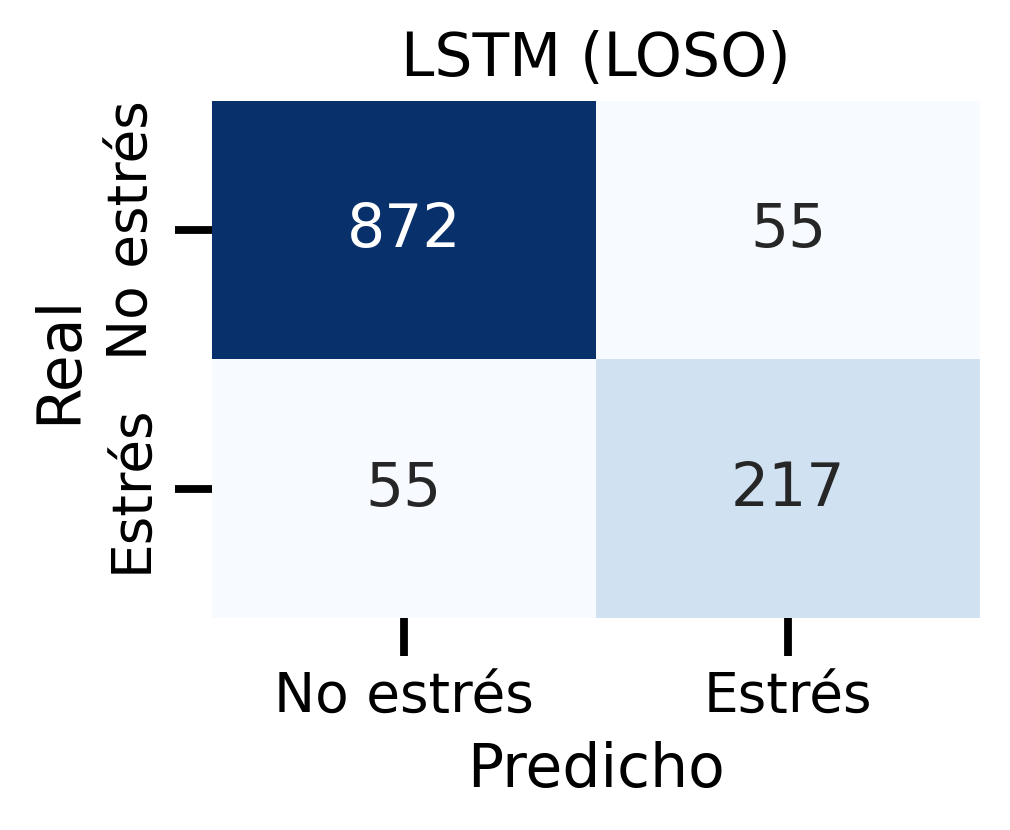

In [24]:
run_seq("LSTM", ARCHS["LSTM"], SEQ_DATA)

CNN: Acc 0.931±0.097 | F1 0.773±0.367 | MCC 0.768±0.360 | AUC 0.976±0.067


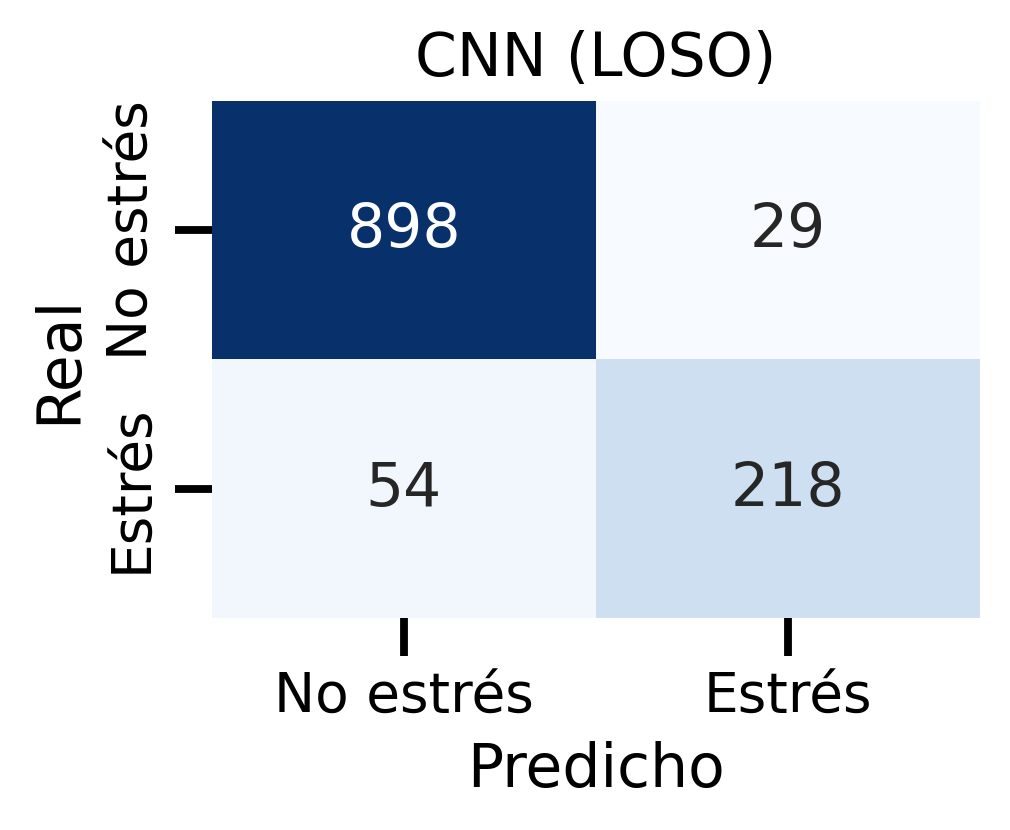

In [25]:
run_seq("CNN", ARCHS["CNN"], SEQ_DATA)

## 9. Comparativa final y elección del modelo
Ranking con la puntuación compuesta (0,4·MCC + 0,4·AUC + 0,2·F1) sobre los modelos principales: clásicos y secuenciales, **sin personalizar** (la personalización se analiza en la sección 6 pero no compite, porque exigiría una sesión de calibración en el espejo).



In [26]:
FINAL = ["Baseline_mayoritaria", "Baseline_umbral_EDA"] + list(MODELS) + ["LSTM", "CNN"]
display(summary_table(FINAL))

cand = means_table(MAIN_NAMES)
cand["Composite"] = 0.4 * cand["MCC"] + 0.4 * cand["AUC"] + 0.2 * cand["F1"]
TOP3 = cand.sort_values("Composite", ascending=False).head(3)
print("\n TOP 3")
display(TOP3[["F1", "MCC", "AUC", "Composite"]].round(3))
BEST = TOP3.index[0]
print("Modelo elegido para los análisis siguientes y para el Notebook 2:", BEST)

,Acc,F1,MCC,AUC,Recall,Specificity
Baseline_mayoritaria,0.779±0.009,0.000±0.000,0.000±0.000,0.500±0.000,0.000±0.000,1.000±0.000
Baseline_umbral_EDA,0.584±0.270,0.184±0.206,0.057±0.152,0.904±0.110,0.418±0.497,0.630±0.482
SVM,0.904±0.090,0.697±0.336,0.695±0.319,0.928±0.160,0.700±0.395,0.962±0.081
RF,0.929±0.056,0.829±0.146,0.804±0.159,0.984±0.029,0.823±0.213,0.959±0.061
XGBoost,0.932±0.057,0.835±0.146,0.814±0.152,0.990±0.018,0.822±0.214,0.964±0.067
LR,0.887±0.121,0.737±0.278,0.723±0.259,0.971±0.047,0.809±0.342,0.908±0.158
AdaBoost,0.894±0.090,0.757±0.222,0.730±0.227,0.966±0.070,0.800±0.290,0.921±0.119
KNN,0.889±0.076,0.663±0.302,0.638±0.304,0.886±0.156,0.625±0.340,0.965±0.051
LSTM,0.908±0.121,0.736±0.398,0.702±0.434,0.903±0.217,0.793±0.411,0.942±0.112
CNN,0.931±0.097,0.773±0.367,0.768±0.360,0.976±0.067,0.797±0.388,0.970±0.081



 TOP 3


,F1,MCC,AUC,Composite
XGBoost,0.835,0.814,0.990,0.889
RF,0.829,0.804,0.984,0.881
CNN,0.773,0.768,0.976,0.852


Modelo elegido para los análisis siguientes y para el Notebook 2: XGBoost


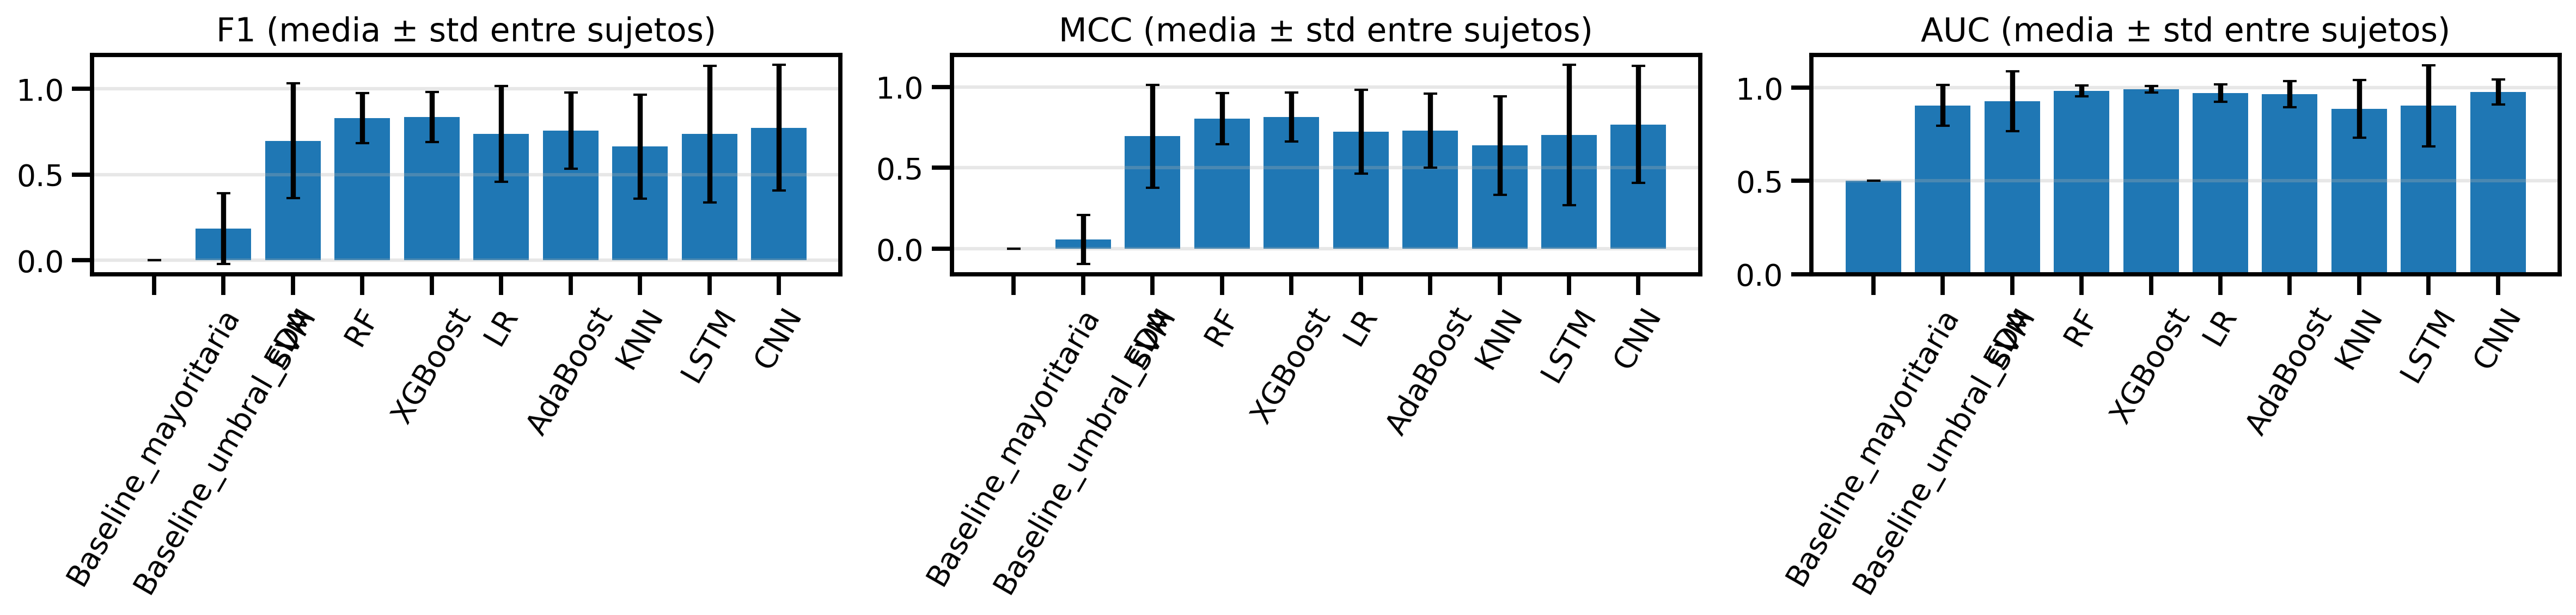

In [27]:
names = FINAL
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axes, ["F1", "MCC", "AUC"]):
    mu = [RES[n][m].mean() for n in names]
    sd = [RES[n][m].std() for n in names]
    ax.bar(names, mu, yerr=sd, capsize=3)
    ax.set_title(f"{m} (media ± std entre sujetos)")
    ax.tick_params(axis="x", rotation=60)
    ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_POSTER}/metricas_modelos.png', bbox_inches='tight')
plt.show()

## 10. Variación entre personas y análisis de errores
Cuánto cambia el rendimiento de una persona a otra y dónde se producen los falsos positivos.

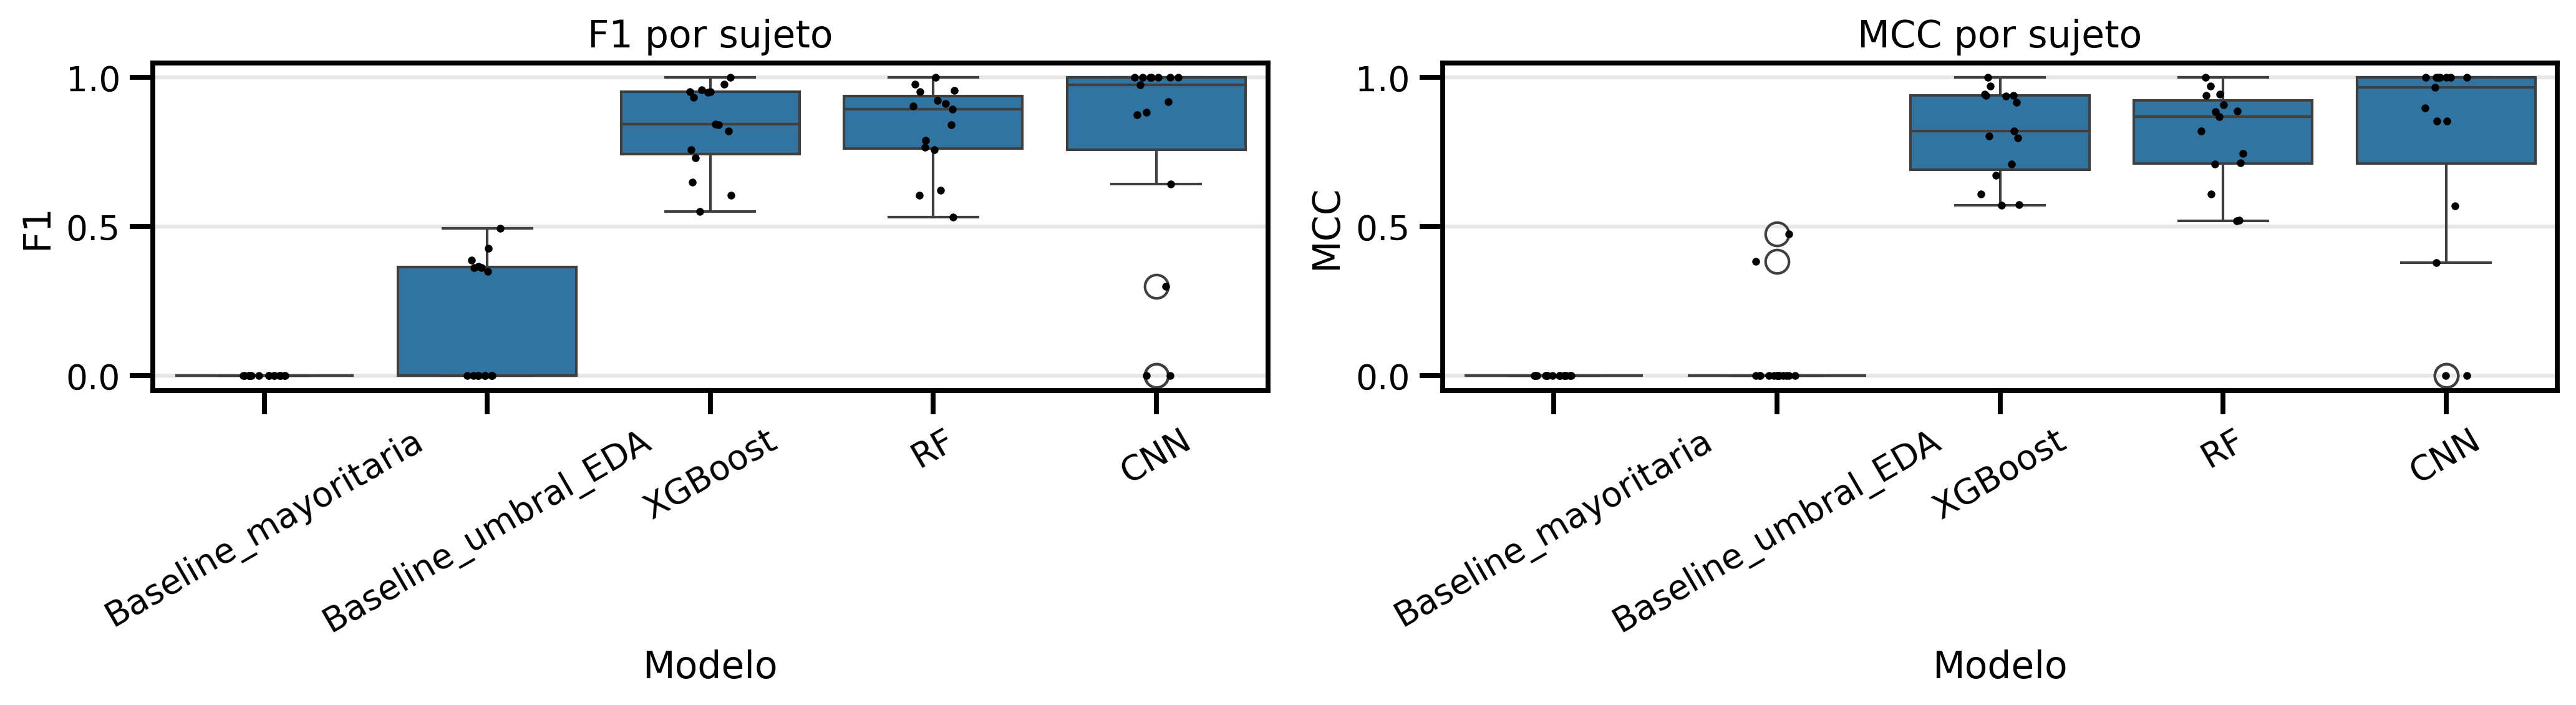

In [28]:
sel = ["Baseline_mayoritaria", "Baseline_umbral_EDA"] + list(TOP3.index)
long = pd.concat([RES[n][["F1", "MCC"]].assign(Modelo=n) for n in sel]).reset_index()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, m in zip(axes, ["F1", "MCC"]):
    sns.boxplot(data=long, x="Modelo", y=m, ax=ax)
    sns.stripplot(data=long, x="Modelo", y=m, ax=ax, color="black", size=3)
    ax.set_title(f"{m} por sujeto"); ax.tick_params(axis="x", rotation=30); ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(f'{OUT_POSTER}/variacion_sujetos_cajas.png', bbox_inches='tight')
plt.show()

In [29]:
print("Modelo:", BEST)
display(RES[BEST].round(3))
print("Peores sujetos (F1):", RES[BEST].F1.sort_values().head(3).round(3).to_dict())

Modelo: XGBoost


,Acc,F1,MCC,AUC,Precision,Recall,Specificity,FPR
Subject,,,,,,,,
S10,0.932,0.844,0.804,0.952,0.905,0.792,0.975,0.025
S11,0.833,0.730,0.672,0.998,0.575,1.000,0.785,0.215
S13,0.863,0.759,0.710,1.000,0.611,1.000,0.825,0.175
S14,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.000
S15,0.871,0.606,0.610,0.998,1.000,0.435,1.000,0.000
S16,0.990,0.978,0.972,0.999,0.957,1.000,0.987,0.013
S17,0.980,0.958,0.945,0.999,0.958,0.958,0.987,0.013
S2,0.865,0.649,0.575,0.953,0.750,0.571,0.947,0.053
S3,0.939,0.842,0.821,0.992,1.000,0.727,1.000,0.000


Peores sujetos (F1): {'S9': 0.552, 'S15': 0.606, 'S2': 0.649}


En Baseline/Amusement/Meditation, pct_predicho_estres = tasa de falsos positivos; en Stress = recall.


,n,pct_predicho_estres,p_media
Cond,,,
Baseline,587,0.036,0.052
Amusement,186,0.043,0.067
Meditation,394,0.036,0.042
Stress,332,0.822,0.811


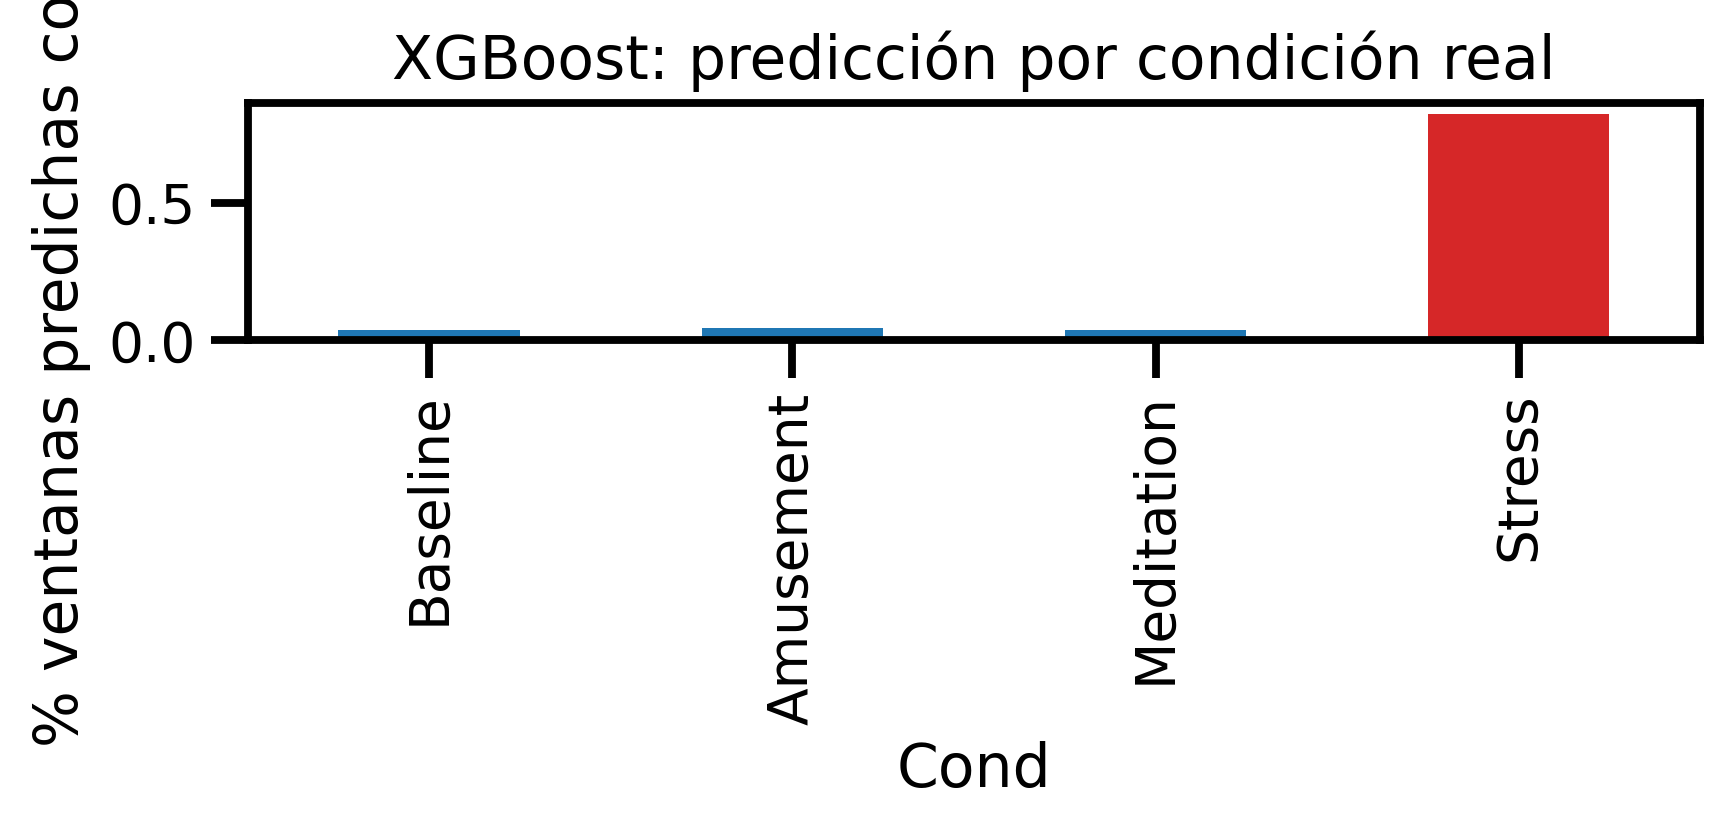

In [30]:
o = OOF[BEST].copy()
o["pred"] = (o.p >= 0.5).astype(int)
by_cond = (o.groupby("Cond").agg(n=("y", "size"), pct_predicho_estres=("pred", "mean"), p_media=("p", "mean"))
             .reindex(["Baseline", "Amusement", "Meditation", "Stress"]))
print("En Baseline/Amusement/Meditation, pct_predicho_estres = tasa de falsos positivos; en Stress = recall.")
display(by_cond.round(3))
by_cond["pct_predicho_estres"].plot(kind="bar", color=["tab:blue", "tab:blue", "tab:blue", "tab:red"], figsize=(6, 3))
plt.ylabel("% ventanas predichas como estrés"); plt.title(f"{BEST}: predicción por condición real")
plt.tight_layout()
plt.savefig(f'{OUT_POSTER}/tasa_falsos_positivos.png', bbox_inches='tight')
plt.show()

## 11. Incertidumbre y abstención
La confianza de una ventana es `max(p, 1-p)`. Si es baja, el servicio **se abstiene** en lugar de interpretar. Se muestra la calibración de las probabilidades y cómo mejora el rendimiento al aumentar la exigencia (a costa de cubrir menos ventanas).

Brier score (XGBoost): 0.049


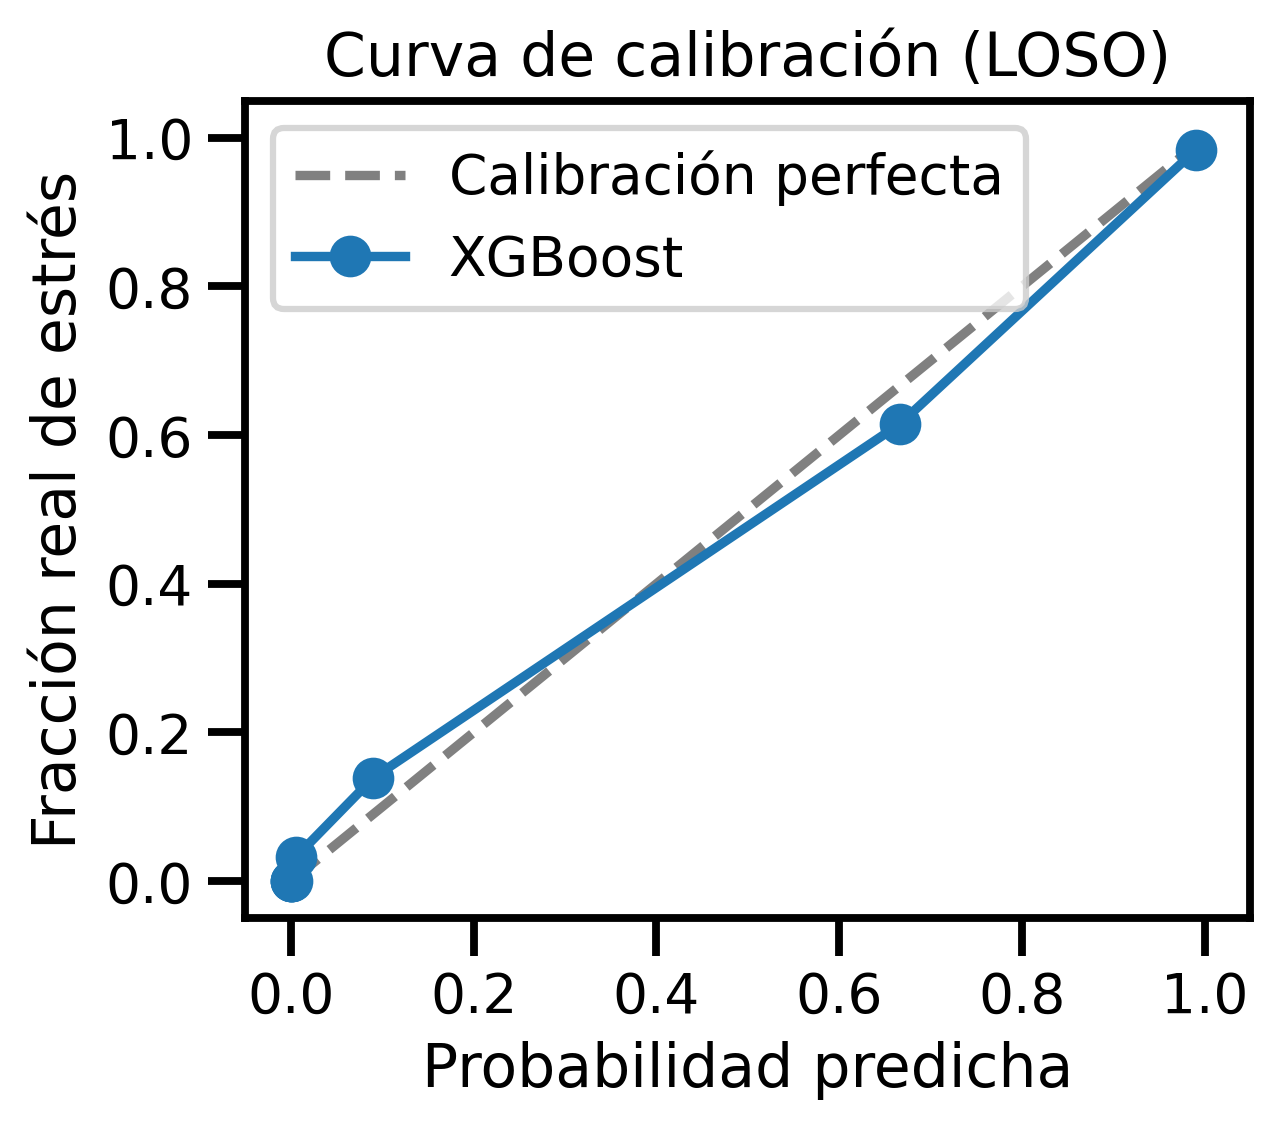

In [31]:
o = OOF[BEST]
prob_true, prob_pred = calibration_curve(o.y, o.p, n_bins=8, strategy="quantile")
print(f"Brier score ({BEST}): {brier_score_loss(o.y, o.p):.3f}")
plt.figure(figsize=(4.5, 4))
plt.plot([0, 1], [0, 1], "--", color="gray", label="Calibración perfecta")
plt.plot(prob_pred, prob_true, "o-", label=BEST)
plt.xlabel("Probabilidad predicha"); plt.ylabel("Fracción real de estrés")
plt.title("Curva de calibración (LOSO)"); plt.legend(); plt.tight_layout()
plt.savefig(f'{OUT_POSTER}/curva_calibracion.png', bbox_inches='tight')
plt.show()

,cobertura,F1,MCC
umbral_confianza,,,
0.5,1.000,0.843,0.800
0.6,0.968,0.868,0.833
0.7,0.942,0.892,0.864
0.8,0.911,0.919,0.900
0.9,0.853,0.945,0.933


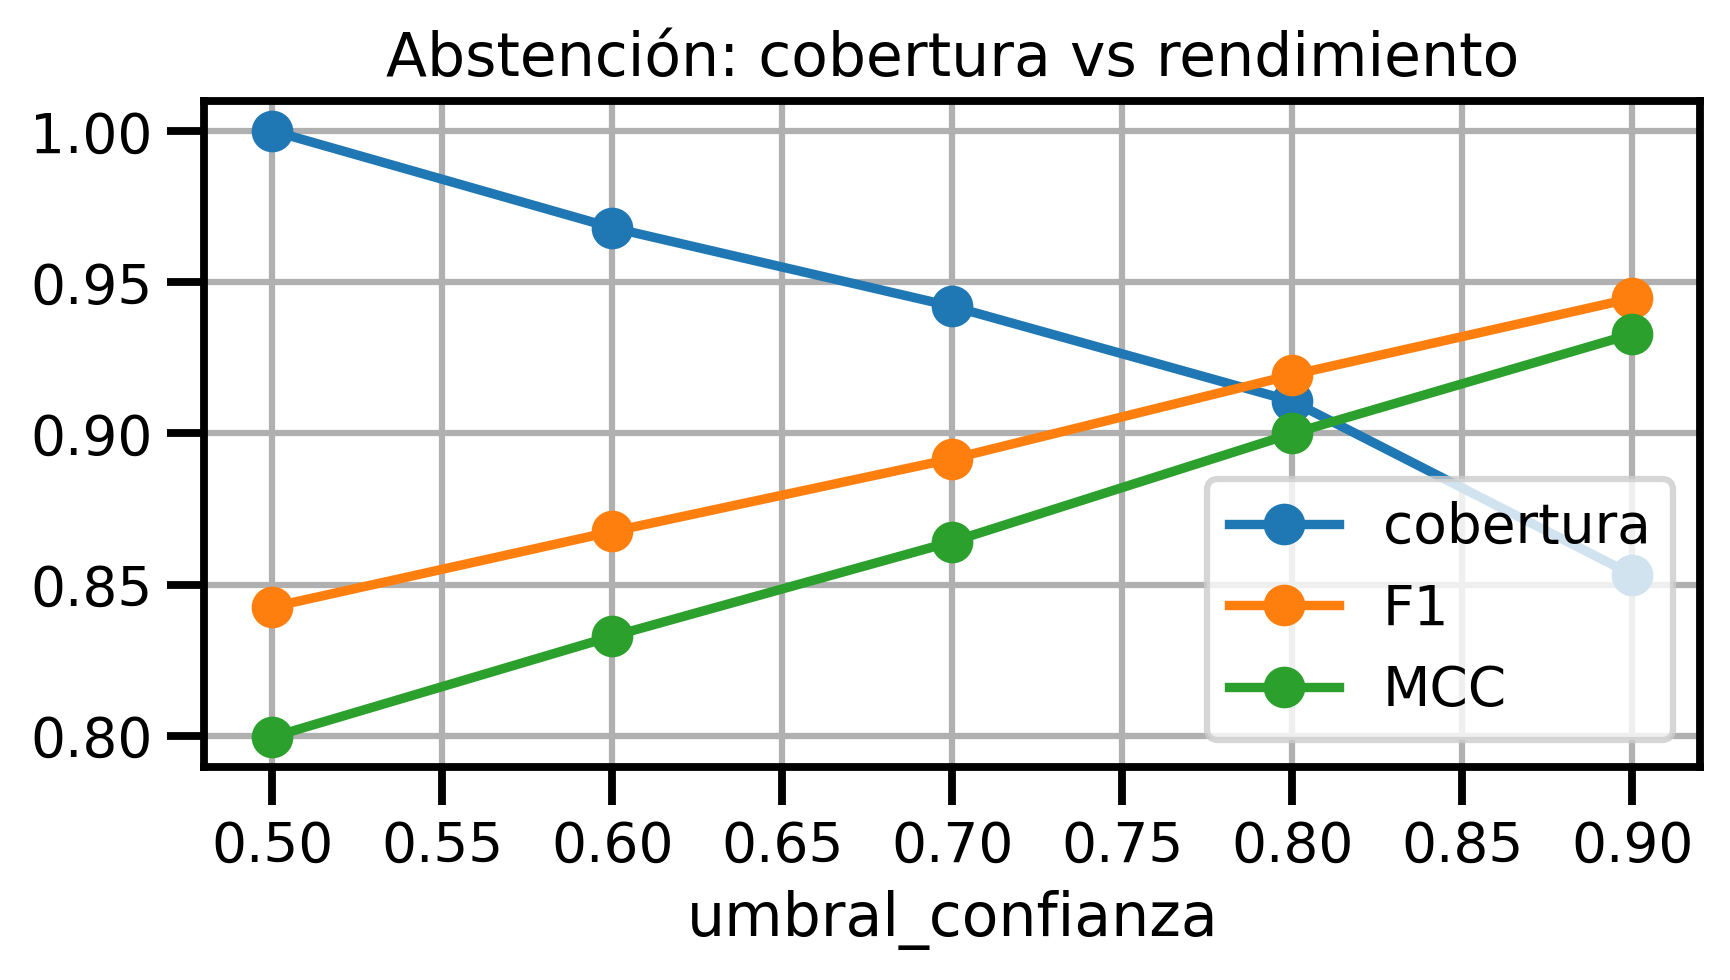

In [32]:
conf = np.maximum(o.p.values, 1 - o.p.values)
rows = []
for tau in [0.5, 0.6, 0.7, 0.8, 0.9]:
    m = conf >= tau
    if m.sum() < 10 or len(np.unique(o.y.values[m])) < 2:
        continue
    yh = (o.p.values[m] >= 0.5).astype(int)
    rows.append({"umbral_confianza": tau, "cobertura": m.mean(),
                 "F1": f1_score(o.y.values[m], yh, zero_division=0),
                 "MCC": matthews_corrcoef(o.y.values[m], yh)})
abst = pd.DataFrame(rows).set_index("umbral_confianza")
display(abst.round(3))
abst[["cobertura", "F1", "MCC"]].plot(marker="o", figsize=(6, 3.5), grid=True)
plt.title("Abstención: cobertura vs rendimiento"); plt.tight_layout()
plt.savefig(f'{OUT_POSTER}/curva_abstencion.png', bbox_inches='tight')
plt.show()

## 12. Exportación para el Notebook 2 y limitaciones
Se guardan en `outputs`:
- `resultados_resumen.csv` y `resultados_por_sujeto.csv`: tablas de métricas.
- `dataset_features.csv`: todas las ventanas con sus features (pecho, 60 s) y condición.
- `OOF_best_model.csv` y `OOF_modelos_principales.csv`: probabilidades fuera de muestra (LOSO) del modelo elegido y de los principales.
- `modelo_final.pkl` (+ `modelo_final.pt` si el modelo elegido es LSTM o CNN): el modelo elegido **reentrenado con todos los sujetos**, junto con su escalador y los metadatos para cargarlo.

**Limitaciones**
- **Pocos sujetos y datos de laboratorio**: solo 15 personas en un entorno controlado. El rendimiento en uso real (movimiento, ruido, otras situaciones de estrés) puede ser menor.
- **Variación entre personas**: el rendimiento cambia mucho de un sujeto a otro. En los peores casos el modelo ordena bien las ventanas (AUC alto) pero el umbral fijo de 0,5 no es adecuado para esa persona.
- **Posible sesgo por habla y movimiento**: la tarea de estrés incluye hablar en público, y ACC y EMG pueden estar captando esa actividad y no solo la respuesta fisiológica. La ablación (sección 7) muestra que las demás señales añadidas aportan poco más de lo que ya dan EDA y HRV, con diferencias menores que la variación entre sujetos.
- **Personalización**: con solo `N_CALIB` ventanas de baseline la normalización por usuario no mejoró los resultados (sección 6), así que el modelo elegido no se personaliza.
- **Modelos comparables**: los mejores modelos clásicos obtienen resultados muy parecidos, por lo que la elección del modelo final no es concluyente. Los modelos secuenciales disponen de menos muestras.
- **Inferencia en vivo (Notebook 2)**: es una reproducción de sesiones grabadas, no sensores reales. Además, el modelo final se entrenó con todos los sujetos, incluido el que se muestra, así que su probabilidad es optimista. La probabilidad LOSO es la que refleja el rendimiento real.
- **Uso previsto**: el servicio estima compatibilidad con estrés con una confianza asociada y propone acciones voluntarias. No es una herramienta de diagnóstico.

In [33]:
# Tablas de resultados
summary_table(list(RES)).to_csv(f"{OUT_POSTER}/resultados_resumen.csv")
pd.concat([RES[n].assign(Modelo=n) for n in RES]).to_csv(f"{OUT_POSTER}/resultados_por_sujeto.csv")

# Datos para el Notebook 2
DF.to_csv(f"{OUT_POSTER}/dataset_features.csv", index=False)
OOF[BEST].to_csv(f"{OUT_POSTER}/OOF_best_model.csv", index=False)
pd.concat([OOF[n].assign(Modelo=n) for n in MAIN_NAMES]).to_csv(f"{OUT_POSTER}/OOF_modelos_principales.csv", index=False)

# Modelo final: reentrenado con todos los datos (sin personalizar, igual que el OOF)
META = {"name": BEST, "cols": COLS_ALL, "step_sec": STEP_SEC, "window_sec": WINDOW_SEC}
if BEST in MODELS:
    y_full = DF["Label"].values
    modelo_final = MODELS[BEST](y_full)
    modelo_final.fit(DF[COLS_ALL], y_full)
    META.update(kind="classic", model=modelo_final)
else:
    modelo_final, scaler = fit_seq_model(ARCHS[BEST], SEQ_DATA[0], SEQ_DATA[1])
    modelo_final = modelo_final.eval().cpu()
    ts_model = torch.jit.trace(modelo_final, torch.zeros(1, SEQ_LEN, len(COLS_ALL)))
    torch.jit.save(ts_model, f"{OUT_POSTER}/modelo_final.pt")
    META.update(kind="seq", seq_len=SEQ_LEN, scaler=scaler, torchscript="modelo_final.pt")
joblib.dump(META, f"{OUT_POSTER}/modelo_final.pkl")
print(f"Exportado en {OUT_POSTER}: modelo final = {BEST} ({META['kind']})")

Exportado en ./outputs: modelo final = XGBoost (classic)
